# Adiabatic numerical contours at $T(0^+)=0.1\,\mathrm{MeV}$

The first figure shows the **nonrelativistic full numerical solution** in the supplied reference style. The second overlays it with the **saved relativistic numerical contour** using the same colors for equal speeds and different line styles.

Both datasets use massless quarks, massive QMC-RMF3 pure neutron matter, and the cold $3n_0$ calibration, with $B^{1/4}=189.1565957288247\,\mathrm{MeV}$. The nonrelativistic calculation conserves baryon flux, pressure, and enthalpy flux and uses the full EOS.

**Interpretation:** the relativistic curve is the historical August 24 calculation; the new curve uses the revised weak rate and transport coupling. This overlay compares the saved calculations and does **not** isolate the effect of relativity at fixed microphysics. The gray regions reproduce the thermodynamic boundaries in the supplied reference figure; they do not define the data mask.

The original nonrelativistic grid reaches only about $4023\,\mathrm{m/s}$. Separately saved numerical extensions now bracket $5000\,\mathrm{m/s}$ on all 30 rays and connect the $50\,\mathrm{m/s}$ inner contour. No missing speed values are extrapolated. Running this notebook loads the saved solutions and exports figures; it does not rerun either full scan.

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "RMFsolver/phase_velocity.py").is_file())
BASE_PATH = ROOT / "new_paper_calculations/26-10-24/T0plus0p1-adiabatic-slow.npy"
RELATIVISTIC_PATH = ROOT / "new_paper_calculations/26-10-24/inputs/relativistic-state-of-art.npy"
DOMAIN_PATH = ROOT / "new_paper_calculations/26-10-24/T0plus0p1-domain.npy"
EXTENSION_PATH = ROOT / "new_paper_calculations/26-10-26/nonrel-contour-extension.npy"

nonrel = np.load(BASE_PATH, allow_pickle=True).item()
rel = np.load(RELATIVISTIC_PATH, allow_pickle=True).item()
domain = np.load(DOMAIN_PATH, allow_pickle=True).item()
extension = np.load(EXTENSION_PATH, allow_pickle=True).item()
assert nonrel["all_targets_successful"] and extension["complete"]
assert nonrel["hydrodynamic_model"] == "nonrelativistic_isobaric" and nonrel["closure"] == "adiabatic"
assert np.array_equal(nonrel["T_0plus_values_MeV"], [.1]) and rel["T_0plus_MeV"] == .1
assert nonrel["calibration"] == rel["calibration"]
assert extension["identity"]["base_sha256"] == hashlib.sha256(BASE_PATH.read_bytes()).hexdigest()
assert nonrel["reference_source_sha256"] == hashlib.sha256(RELATIVISTIC_PATH.read_bytes()).hexdigest()
assert np.all(nonrel["numerical_outward_success_grid"]) and np.all(rel["plot_success_grid"])

# Actual curvilinear coordinates; the outer radial fraction is angle dependent.
NR_BASE = tuple(np.asarray(nonrel[key], dtype=float)[..., 0] for key in (
    "nB_0minus_over_n0_grid", "T_0minus_MeV_grid", "numerical_outward_u_0minus_m_s_grid"))
REL_GRID = tuple(np.asarray(rel[key], dtype=float) for key in (
    "plot_nB_0minus_over_n0_grid", "plot_T_0minus_MeV_grid", "plot_u_0minus_m_s_grid"))
assert all(np.allclose(a, b, rtol=1e-13, atol=1e-12) for a, b in zip(NR_BASE[:2], REL_GRID[:2]))
rays = [extension["rays"][i] for i in range(NR_BASE[0].shape[0])]
assert all(row["success"] and row["inner"]["speed"] < 50 and
           row["lower"]["speed"] < 5000 < row["upper"]["speed"] for row in rays)
NR_GRID = tuple(np.column_stack(([row["inner"][field] for row in rays], body))
                for field, body in zip(("nB_0minus_over_n0", "T_0minus_MeV", "speed"), NR_BASE))
NR_OUTER_STRIP = tuple(np.array([[row[end][field] for end in ("lower", "upper")] for row in rays])
                      for field in ("nB_0minus_over_n0", "T_0minus_MeV", "speed"))
BOUNDARY = domain["boundary_diagnostics"]["semi_analytic"]
TRANSFORM = domain["transform"]


def boundary_curve(records, samples):
    ordered = sorted(records, key=lambda r: r["theta_rad"])
    theta_nodes = np.array([r["theta_rad"] for r in ordered])
    theta = np.linspace(theta_nodes[0], theta_nodes[-1], samples)
    rho = np.interp(theta, theta_nodes, [r["rho"] for r in ordered])
    return (TRANSFORM["density_origin_over_n0"] + TRANSFORM["density_scale_over_n0"] * rho * np.cos(theta),
            TRANSFORM["temperature_scale_MeV"] * rho * np.sin(theta))


def label_positions(contours, temperature_targets):
    # Position labels on the computed contour segments at the requested height.
    positions = []
    for level, segments in zip(contours.levels, contours.allsegs):
        segments = [s for s in segments if len(s) >= 2]
        if not segments:
            continue
        segment = max(segments, key=len)
        target = temperature_targets[float(level)]
        order = np.argsort(segment[:, 1])
        temperature = float(np.clip(target, segment[:, 1].min(), segment[:, 1].max()))
        density = float(np.interp(temperature, segment[order, 1], segment[order, 0]))
        positions.append((density, temperature))
    return positions


print(f"Original nonrelativistic grid: {NR_BASE[0].shape}, all 540 points accepted")
print(f"Supplementary accepted BVPs: {sum(len(row['accepted']) for row in rays)}")
print(f"5000 m/s brackets: {len(rays)}/30; maximum fraction width: "
      f"{max(row['upper']['fraction']-row['lower']['fraction'] for row in rays):.5f}")
print("Relativistic data: saved August 24 reference; nonrelativistic data: October 24 + October 26 extension.")

Original nonrelativistic grid: (30, 18), all 540 points accepted
Supplementary accepted BVPs: 209
5000 m/s brackets: 30/30; maximum fraction width: 0.00250
Relativistic data: saved August 24 reference; nonrelativistic data: October 24 + October 26 extension.


## Nonrelativistic contour

Colored lines and gray exclusions follow the reference image. Each plotting cell has its own tuning block; figures are exported as both PNG and PDF to `local_analysis_results/26-10-26/`.

Saved /Users/janshao/NSM_related/local_analysis_results/26-10-26/adiabatic-nonrelativistic-contour.png and PDF


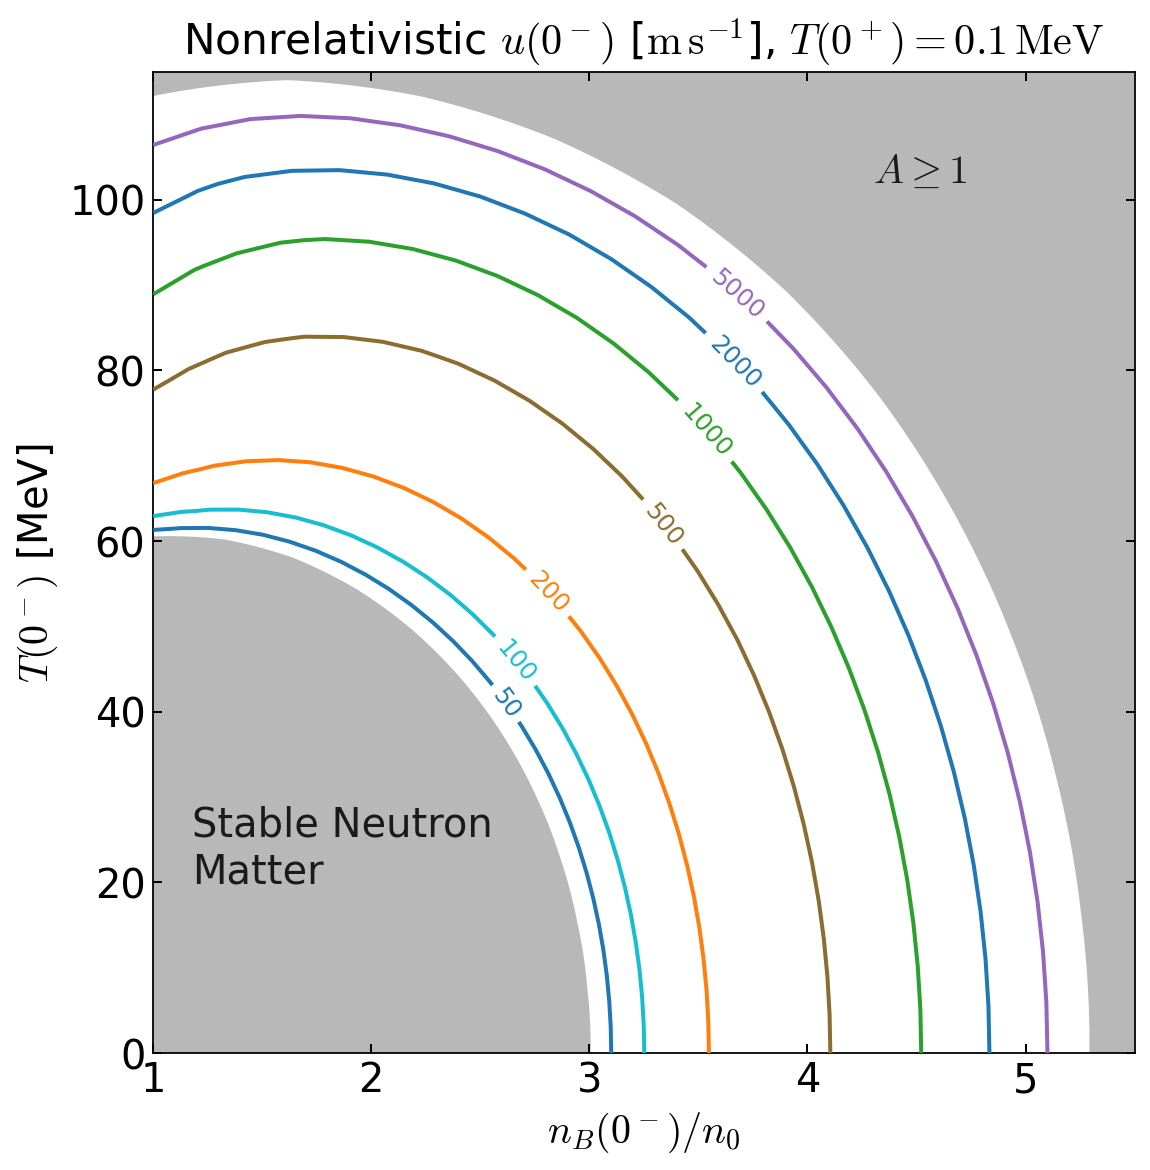

In [2]:
# Tunable plotting parameters
VELOCITY_CONTOUR_LEVELS_M_S = (50., 100., 200., 500., 1000., 2000., 5000.)
VELOCITY_CONTOUR_COLORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c", "#1f77b4", "#9467bd")
NONRELATIVISTIC_LINE_STYLE = "-"
NONRELATIVISTIC_LINE_WIDTH = 1.8
NONRELATIVISTIC_ALPHA = 1.0
CONTOUR_ZORDER = 3
CONTOUR_LABEL_FONT_SIZE = 11
CONTOUR_LABEL_FORMAT = "%g"
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 4
CONTOUR_LABEL_FACE_COLOR = "white"
CONTOUR_LABEL_EDGE_COLOR = "none"
CONTOUR_LABEL_BOX_PADDING = .08
CONTOUR_LABEL_BACKGROUND_ALPHA = 1.
CONTOUR_LABEL_TEMPERATURES = {50.: 41., 100.: 46., 200.: 54., 500.: 62., 1000.: 73., 2000.: 81., 5000.: 89.}
BOUNDARY_INTERPOLATION_SAMPLES = 401
EXCLUDED_REGION_COLOR = "0.72"
EXCLUDED_REGION_ALPHA = 1.0
EXCLUDED_REGION_ZORDER = 0
A_REGION_TEXT = r"$A\geq 1$"
A_REGION_TEXT_POSITION = (4.3, 102.)
INNER_REGION_TEXT = "Stable Neutron\nMatter"
INNER_REGION_TEXT_POSITION = (1.18, 20.)
REGION_TEXT_COLOR = "0.10"
REGION_TEXT_FONT_SIZE = 18
REGION_TEXT_ZORDER = 5
FIGURE_SIZE = (7.2, 7.2)
FIGURE_DPI = 160
EXPORT_DPI = 220
BACKGROUND_COLOR = "white"
CONSTRAINED_LAYOUT = True
FONT_FAMILY = "DejaVu Sans"
MATH_FONTSET = "cm"
X_LIMITS = (1., 5.5)
Y_LIMITS_MEV = (0., 115.)
X_SCALE = "linear"
Y_SCALE = "linear"
X_TICKS = (1., 2., 3., 4., 5.)
Y_TICKS_MEV = (0., 20., 40., 60., 80., 100.)
BOX_ASPECT = 1.
TITLE = r"Nonrelativistic $u(0^-)$ [$\mathrm{m\,s^{-1}}$], $T(0^+)=0.1\,\mathrm{MeV}$"
TITLE_FONT_SIZE = 19
TITLE_PAD = 8
X_LABEL = r"$n_B(0^-)/n_0$"
Y_LABEL = r"$T(0^-)$ [MeV]"
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
TICK_DIRECTION = "in"
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4
TICK_WIDTH = .9
SPINE_LINE_WIDTH = .8
GRID_ENABLED = False
OUTPUT_STEM = "local_analysis_results/26-10-26/adiabatic-nonrelativistic-contour"

with plt.rc_context({"font.family": FONT_FAMILY, "mathtext.fontset": MATH_FONTSET}):
    figure, axis = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI,
                                constrained_layout=CONSTRAINED_LAYOUT, facecolor=BACKGROUND_COLOR)
    axis.set_facecolor(BACKGROUND_COLOR)
    inner_x, inner_y = boundary_curve(BOUNDARY["gap_curve_records_by_T0plus"][.1], BOUNDARY_INTERPOLATION_SAMPLES)
    outer_x, outer_y = boundary_curve(BOUNDARY["A_curve_records"], BOUNDARY_INTERPOLATION_SAMPLES)
    axis.fill(np.r_[inner_x, X_LIMITS[0], inner_x[0]], np.r_[inner_y, Y_LIMITS_MEV[0], Y_LIMITS_MEV[0]],
              color=EXCLUDED_REGION_COLOR, alpha=EXCLUDED_REGION_ALPHA, zorder=EXCLUDED_REGION_ZORDER)
    axis.fill(np.r_[outer_x, X_LIMITS[0], X_LIMITS[1], X_LIMITS[1], outer_x[0]],
              np.r_[outer_y, Y_LIMITS_MEV[1], Y_LIMITS_MEV[1], Y_LIMITS_MEV[0], Y_LIMITS_MEV[0]],
              color=EXCLUDED_REGION_COLOR, alpha=EXCLUDED_REGION_ALPHA, zorder=EXCLUDED_REGION_ZORDER)

    body_levels = [v for v in VELOCITY_CONTOUR_LEVELS_M_S if v < 5000.]
    body_colors = [c for v, c in zip(VELOCITY_CONTOUR_LEVELS_M_S, VELOCITY_CONTOUR_COLORS) if v < 5000.]
    outer_levels = [v for v in VELOCITY_CONTOUR_LEVELS_M_S if v == 5000.]
    outer_colors = [c for v, c in zip(VELOCITY_CONTOUR_LEVELS_M_S, VELOCITY_CONTOUR_COLORS) if v == 5000.]
    if any(v > 5000. for v in VELOCITY_CONTOUR_LEVELS_M_S):
        raise ValueError("Additional levels above 5000 m/s require additional numerical coverage")
    contour_sets = []
    for data, levels, colors in ((NR_GRID, body_levels, body_colors), (NR_OUTER_STRIP, outer_levels, outer_colors)):
        if not levels:
            continue
        contours = axis.contour(*data, levels=levels, colors=colors,
                                linestyles=NONRELATIVISTIC_LINE_STYLE, linewidths=NONRELATIVISTIC_LINE_WIDTH,
                                alpha=NONRELATIVISTIC_ALPHA, zorder=CONTOUR_ZORDER)
        labels = axis.clabel(contours, inline=CONTOUR_LABEL_INLINE, fmt=CONTOUR_LABEL_FORMAT,
                    fontsize=CONTOUR_LABEL_FONT_SIZE, inline_spacing=CONTOUR_LABEL_INLINE_SPACING,
                    manual=label_positions(contours, CONTOUR_LABEL_TEMPERATURES))
        for label in labels:
            label.set_bbox(dict(facecolor=CONTOUR_LABEL_FACE_COLOR, edgecolor=CONTOUR_LABEL_EDGE_COLOR,
                                boxstyle=f"square,pad={CONTOUR_LABEL_BOX_PADDING}",
                                alpha=CONTOUR_LABEL_BACKGROUND_ALPHA))
        contour_sets.append(contours)

    axis.text(*A_REGION_TEXT_POSITION, A_REGION_TEXT, color=REGION_TEXT_COLOR,
              fontsize=REGION_TEXT_FONT_SIZE, zorder=REGION_TEXT_ZORDER)
    axis.text(*INNER_REGION_TEXT_POSITION, INNER_REGION_TEXT, color=REGION_TEXT_COLOR,
              fontsize=REGION_TEXT_FONT_SIZE, zorder=REGION_TEXT_ZORDER)
    axis.set_xlim(*X_LIMITS)
    axis.set_ylim(*Y_LIMITS_MEV)
    axis.set_xscale(X_SCALE)
    axis.set_yscale(Y_SCALE)
    axis.set_xticks(X_TICKS)
    axis.set_yticks(Y_TICKS_MEV)
    axis.set_box_aspect(BOX_ASPECT)
    axis.set_xlabel(X_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_ylabel(Y_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_title(TITLE, fontsize=TITLE_FONT_SIZE, pad=TITLE_PAD)
    axis.tick_params(direction=TICK_DIRECTION, top=TICKS_TOP, right=TICKS_RIGHT,
                     length=TICK_LENGTH, width=TICK_WIDTH, labelsize=TICK_LABEL_FONT_SIZE)
    axis.grid(GRID_ENABLED)
    for spine in axis.spines.values():
        spine.set_linewidth(SPINE_LINE_WIDTH)
    output = ROOT / OUTPUT_STEM
    output.parent.mkdir(parents=True, exist_ok=True)
    figure.savefig(output.with_suffix(".png"), dpi=EXPORT_DPI, facecolor=BACKGROUND_COLOR)
    figure.savefig(output.with_suffix(".pdf"), facecolor=BACKGROUND_COLOR)
    print(f"Saved {output.with_suffix('.png')} and PDF")
    plt.show()


## Historical relativistic and new nonrelativistic overlay

**Solid:** new nonrelativistic solution. **Dashed:** saved relativistic solution. Colors denote the same velocity levels; only the solid curves carry numerical labels to keep the overlap readable. The historical reference retains its original data coverage, including its shorter low-speed curve near the inner boundary.

Saved /Users/janshao/NSM_related/local_analysis_results/26-10-26/adiabatic-relativistic-vs-nonrelativistic.png and PDF


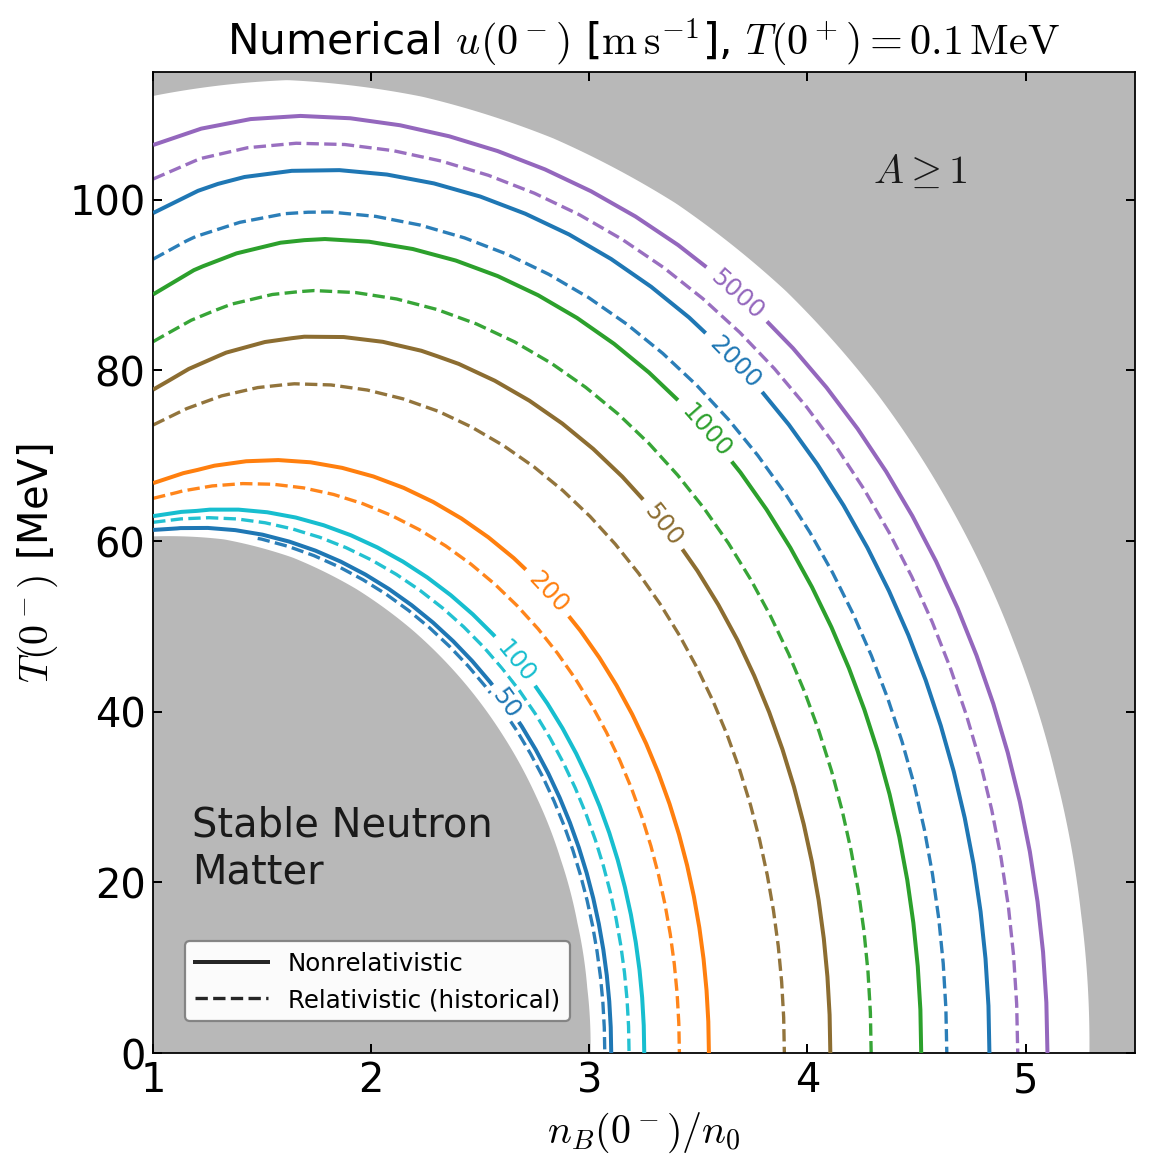

In [3]:
# Tunable plotting parameters
VELOCITY_CONTOUR_LEVELS_M_S = (50., 100., 200., 500., 1000., 2000., 5000.)
VELOCITY_CONTOUR_COLORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c", "#1f77b4", "#9467bd")
NONRELATIVISTIC_LINE_STYLE = "-"
NONRELATIVISTIC_LINE_WIDTH = 1.8
NONRELATIVISTIC_ALPHA = 1.0
CONTOUR_ZORDER = 3
CONTOUR_LABEL_FONT_SIZE = 11
CONTOUR_LABEL_FORMAT = "%g"
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 4
CONTOUR_LABEL_FACE_COLOR = "white"
CONTOUR_LABEL_EDGE_COLOR = "none"
CONTOUR_LABEL_BOX_PADDING = .08
CONTOUR_LABEL_BACKGROUND_ALPHA = 1.
CONTOUR_LABEL_TEMPERATURES = {50.: 41., 100.: 46., 200.: 54., 500.: 62., 1000.: 73., 2000.: 81., 5000.: 89.}
BOUNDARY_INTERPOLATION_SAMPLES = 401
EXCLUDED_REGION_COLOR = "0.72"
EXCLUDED_REGION_ALPHA = 1.0
EXCLUDED_REGION_ZORDER = 0
A_REGION_TEXT = r"$A\geq 1$"
A_REGION_TEXT_POSITION = (4.3, 102.)
INNER_REGION_TEXT = "Stable Neutron\nMatter"
INNER_REGION_TEXT_POSITION = (1.18, 20.)
REGION_TEXT_COLOR = "0.10"
REGION_TEXT_FONT_SIZE = 18
REGION_TEXT_ZORDER = 5
FIGURE_SIZE = (7.2, 7.2)
FIGURE_DPI = 160
EXPORT_DPI = 220
BACKGROUND_COLOR = "white"
CONSTRAINED_LAYOUT = True
FONT_FAMILY = "DejaVu Sans"
MATH_FONTSET = "cm"
X_LIMITS = (1., 5.5)
Y_LIMITS_MEV = (0., 115.)
X_SCALE = "linear"
Y_SCALE = "linear"
X_TICKS = (1., 2., 3., 4., 5.)
Y_TICKS_MEV = (0., 20., 40., 60., 80., 100.)
BOX_ASPECT = 1.
TITLE = r"Numerical $u(0^-)$ [$\mathrm{m\,s^{-1}}$], $T(0^+)=0.1\,\mathrm{MeV}$"
TITLE_FONT_SIZE = 19
TITLE_PAD = 8
X_LABEL = r"$n_B(0^-)/n_0$"
Y_LABEL = r"$T(0^-)$ [MeV]"
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
TICK_DIRECTION = "in"
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4
TICK_WIDTH = .9
SPINE_LINE_WIDTH = .8
GRID_ENABLED = False
OUTPUT_STEM = "local_analysis_results/26-10-26/adiabatic-relativistic-vs-nonrelativistic"
RELATIVISTIC_LINE_STYLE = "--"
RELATIVISTIC_LINE_WIDTH = 1.5
RELATIVISTIC_ALPHA = .95
RELATIVISTIC_ZORDER = 2
LEGEND_LABELS = ("Nonrelativistic", "Relativistic (historical)")
LEGEND_COLOR = "0.15"
LEGEND_FONT_SIZE = 11
LEGEND_LOCATION = "lower left"
LEGEND_ANCHOR = (.02, .02)
LEGEND_FRAME = True
LEGEND_FRAME_ALPHA = .95
LEGEND_FACE_COLOR = "white"
LEGEND_EDGE_COLOR = "0.5"
LEGEND_HANDLE_LENGTH = 3.
LEGEND_ZORDER = 6

with plt.rc_context({"font.family": FONT_FAMILY, "mathtext.fontset": MATH_FONTSET}):
    figure, axis = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI,
                                constrained_layout=CONSTRAINED_LAYOUT, facecolor=BACKGROUND_COLOR)
    axis.set_facecolor(BACKGROUND_COLOR)
    inner_x, inner_y = boundary_curve(BOUNDARY["gap_curve_records_by_T0plus"][.1], BOUNDARY_INTERPOLATION_SAMPLES)
    outer_x, outer_y = boundary_curve(BOUNDARY["A_curve_records"], BOUNDARY_INTERPOLATION_SAMPLES)
    axis.fill(np.r_[inner_x, X_LIMITS[0], inner_x[0]], np.r_[inner_y, Y_LIMITS_MEV[0], Y_LIMITS_MEV[0]],
              color=EXCLUDED_REGION_COLOR, alpha=EXCLUDED_REGION_ALPHA, zorder=EXCLUDED_REGION_ZORDER)
    axis.fill(np.r_[outer_x, X_LIMITS[0], X_LIMITS[1], X_LIMITS[1], outer_x[0]],
              np.r_[outer_y, Y_LIMITS_MEV[1], Y_LIMITS_MEV[1], Y_LIMITS_MEV[0], Y_LIMITS_MEV[0]],
              color=EXCLUDED_REGION_COLOR, alpha=EXCLUDED_REGION_ALPHA, zorder=EXCLUDED_REGION_ZORDER)

    relativistic_contours = axis.contour(*REL_GRID, levels=VELOCITY_CONTOUR_LEVELS_M_S,
                                         colors=VELOCITY_CONTOUR_COLORS, linestyles=RELATIVISTIC_LINE_STYLE,
                                         linewidths=RELATIVISTIC_LINE_WIDTH, alpha=RELATIVISTIC_ALPHA,
                                         zorder=RELATIVISTIC_ZORDER)

    body_levels = [v for v in VELOCITY_CONTOUR_LEVELS_M_S if v < 5000.]
    body_colors = [c for v, c in zip(VELOCITY_CONTOUR_LEVELS_M_S, VELOCITY_CONTOUR_COLORS) if v < 5000.]
    outer_levels = [v for v in VELOCITY_CONTOUR_LEVELS_M_S if v == 5000.]
    outer_colors = [c for v, c in zip(VELOCITY_CONTOUR_LEVELS_M_S, VELOCITY_CONTOUR_COLORS) if v == 5000.]
    if any(v > 5000. for v in VELOCITY_CONTOUR_LEVELS_M_S):
        raise ValueError("Additional levels above 5000 m/s require additional numerical coverage")
    contour_sets = []
    for data, levels, colors in ((NR_GRID, body_levels, body_colors), (NR_OUTER_STRIP, outer_levels, outer_colors)):
        if not levels:
            continue
        contours = axis.contour(*data, levels=levels, colors=colors,
                                linestyles=NONRELATIVISTIC_LINE_STYLE, linewidths=NONRELATIVISTIC_LINE_WIDTH,
                                alpha=NONRELATIVISTIC_ALPHA, zorder=CONTOUR_ZORDER)
        labels = axis.clabel(contours, inline=CONTOUR_LABEL_INLINE, fmt=CONTOUR_LABEL_FORMAT,
                    fontsize=CONTOUR_LABEL_FONT_SIZE, inline_spacing=CONTOUR_LABEL_INLINE_SPACING,
                    manual=label_positions(contours, CONTOUR_LABEL_TEMPERATURES))
        for label in labels:
            label.set_bbox(dict(facecolor=CONTOUR_LABEL_FACE_COLOR, edgecolor=CONTOUR_LABEL_EDGE_COLOR,
                                boxstyle=f"square,pad={CONTOUR_LABEL_BOX_PADDING}",
                                alpha=CONTOUR_LABEL_BACKGROUND_ALPHA))
        contour_sets.append(contours)

    handles = [Line2D([], [], color=LEGEND_COLOR, linestyle=style, linewidth=width, label=label)
               for style, width, label in zip((NONRELATIVISTIC_LINE_STYLE, RELATIVISTIC_LINE_STYLE),
                                              (NONRELATIVISTIC_LINE_WIDTH, RELATIVISTIC_LINE_WIDTH), LEGEND_LABELS)]
    legend = axis.legend(handles=handles, loc=LEGEND_LOCATION, bbox_to_anchor=LEGEND_ANCHOR,
                         fontsize=LEGEND_FONT_SIZE, frameon=LEGEND_FRAME, framealpha=LEGEND_FRAME_ALPHA,
                         facecolor=LEGEND_FACE_COLOR, edgecolor=LEGEND_EDGE_COLOR, handlelength=LEGEND_HANDLE_LENGTH)
    legend.set_zorder(LEGEND_ZORDER)

    axis.text(*A_REGION_TEXT_POSITION, A_REGION_TEXT, color=REGION_TEXT_COLOR,
              fontsize=REGION_TEXT_FONT_SIZE, zorder=REGION_TEXT_ZORDER)
    axis.text(*INNER_REGION_TEXT_POSITION, INNER_REGION_TEXT, color=REGION_TEXT_COLOR,
              fontsize=REGION_TEXT_FONT_SIZE, zorder=REGION_TEXT_ZORDER)
    axis.set_xlim(*X_LIMITS)
    axis.set_ylim(*Y_LIMITS_MEV)
    axis.set_xscale(X_SCALE)
    axis.set_yscale(Y_SCALE)
    axis.set_xticks(X_TICKS)
    axis.set_yticks(Y_TICKS_MEV)
    axis.set_box_aspect(BOX_ASPECT)
    axis.set_xlabel(X_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_ylabel(Y_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_title(TITLE, fontsize=TITLE_FONT_SIZE, pad=TITLE_PAD)
    axis.tick_params(direction=TICK_DIRECTION, top=TICKS_TOP, right=TICKS_RIGHT,
                     length=TICK_LENGTH, width=TICK_WIDTH, labelsize=TICK_LABEL_FONT_SIZE)
    axis.grid(GRID_ENABLED)
    for spine in axis.spines.values():
        spine.set_linewidth(SPINE_LINE_WIDTH)
    output = ROOT / OUTPUT_STEM
    output.parent.mkdir(parents=True, exist_ok=True)
    figure.savefig(output.with_suffix(".png"), dpi=EXPORT_DPI, facecolor=BACKGROUND_COLOR)
    figure.savefig(output.with_suffix(".pdf"), facecolor=BACKGROUND_COLOR)
    print(f"Saved {output.with_suffix('.png')} and PDF")
    plt.show()


## Reproducing the supplementary numerical points

The original datasets remain unchanged. The separately saved inner/outer points were generated with the same solver/EOS source hashes as the original nonrelativistic scan, using only its successful numerical continuation states.

From the repository root, with a working SciPy runtime:

```bash
python3 new_paper_calculations/26-10-26/extend_nonrel_contour.py --workers 4
```

The extension preserves the strict conservation and BVP acceptance gates and records the trials and full accepted profiles. Its upper/lower numerical brackets are narrower than 0.003 in the saved radial-fraction coordinate. No full relativistic solve is launched by this notebook.

## Exact-cold adiabatic analytical contours

Both analytical methods use $T(0^+)=0$ exactly, $\xi=-0.85$, massless quarks and QMC-RMF3 PNM with the same cold $3n_0$ calibration. The full analytical branch uses the quadratic EOS with consistent second-order endpoint heat matching, quadratic ceiling, leading diffusion, and closed $I_2$; the semi-analytical branch follows the full EOS with full diffusion and numerical $I_2$.

The physical cold endpoint has $D_K=\infty$ and $D_K^{-1}=0$, while the integral and speed are finite. No temperature floor is used. Shading is calculated independently for each method. Curves consist of validated level crossings; excluded or failed samples are not interpolated through.

The numerical overlay retains the **$T(0^+)=0.1\,\mathrm{MeV}$** dataset. Its differences from these exact-cold curves include the interface temperature, so this is not a comparison at identical interface conditions. The existing numerical figures above are unchanged.

The full-analytical data and figures below replace the earlier leading-density endpoint calculation. The corrected scan has 61 rays and resolves all seven requested speed levels through 5000 m/s. The semi-analytical data are unchanged.

In [14]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "RMFsolver/phase_velocity.py").is_file())
sys.path.insert(0, str(ROOT / "new_paper_calculations/26-10-26/shared"))
from cold_plot import segments, boundary_segments, excluded_polygons, label_point
COLD_PATH = ROOT / "new_paper_calculations/26-10-26/local/adiabatic-T0plus0-xi-minus0p85.npy"
cold = np.load(COLD_PATH, allow_pickle=True).item()
assert cold["complete"], "Resolve coverage/failures before plotting production contours"
assert set(cold["coverage"]) == {"analytic", "semi_analytic"}, "Both method scans are required"
assert all(not c["failures"] and not c["unresolved"] and not c["unresolved_boundaries"] for c in cold["coverage"].values())
assert cold["identity"]["physics"]["T_0plus_MeV"] == 0
assert cold["identity"]["physics"]["xi"] == -.85
assert cold["calibration"] == nonrel["calibration"]
assert cold["method_eos_approximations"]["analytic"] == "quadratic_pressure_second_order_density"
assert all(identity["physics"] == cold["identity"]["physics"] for identity in cold["method_identities"].values())
print("Full analytical: corrected second-order endpoint; semi-analytical: original full-EOS scan.")
for method, coverage in cold["coverage"].items():
    print(method, coverage)
print("Analytical interfaces: exactly 0 MeV; numerical reference: 0.1 MeV.")
print("Differences include the interface temperature as well as analytical approximations.")


Full analytical: corrected second-order endpoint; semi-analytical: original full-EOS scan.
analytic {'rays': 61, 'failures': 0, 'unresolved': 0, 'unresolved_boundaries': 0, 'supported_levels': [50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0, 5000.0], 'outside_window_levels': []}
semi_analytic {'rays': 61, 'failures': 0, 'unresolved': 0, 'unresolved_boundaries': 0, 'supported_levels': [50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0, 5000.0], 'outside_window_levels': []}
Analytical interfaces: exactly 0 MeV; numerical reference: 0.1 MeV.
Differences include the interface temperature as well as analytical approximations.


### Full analytical

Saved /Users/janshao/NSM_related/local_analysis_results/26-10-26/adiabatic-full-analytical-cold — levels outside window: {'analytic': []}


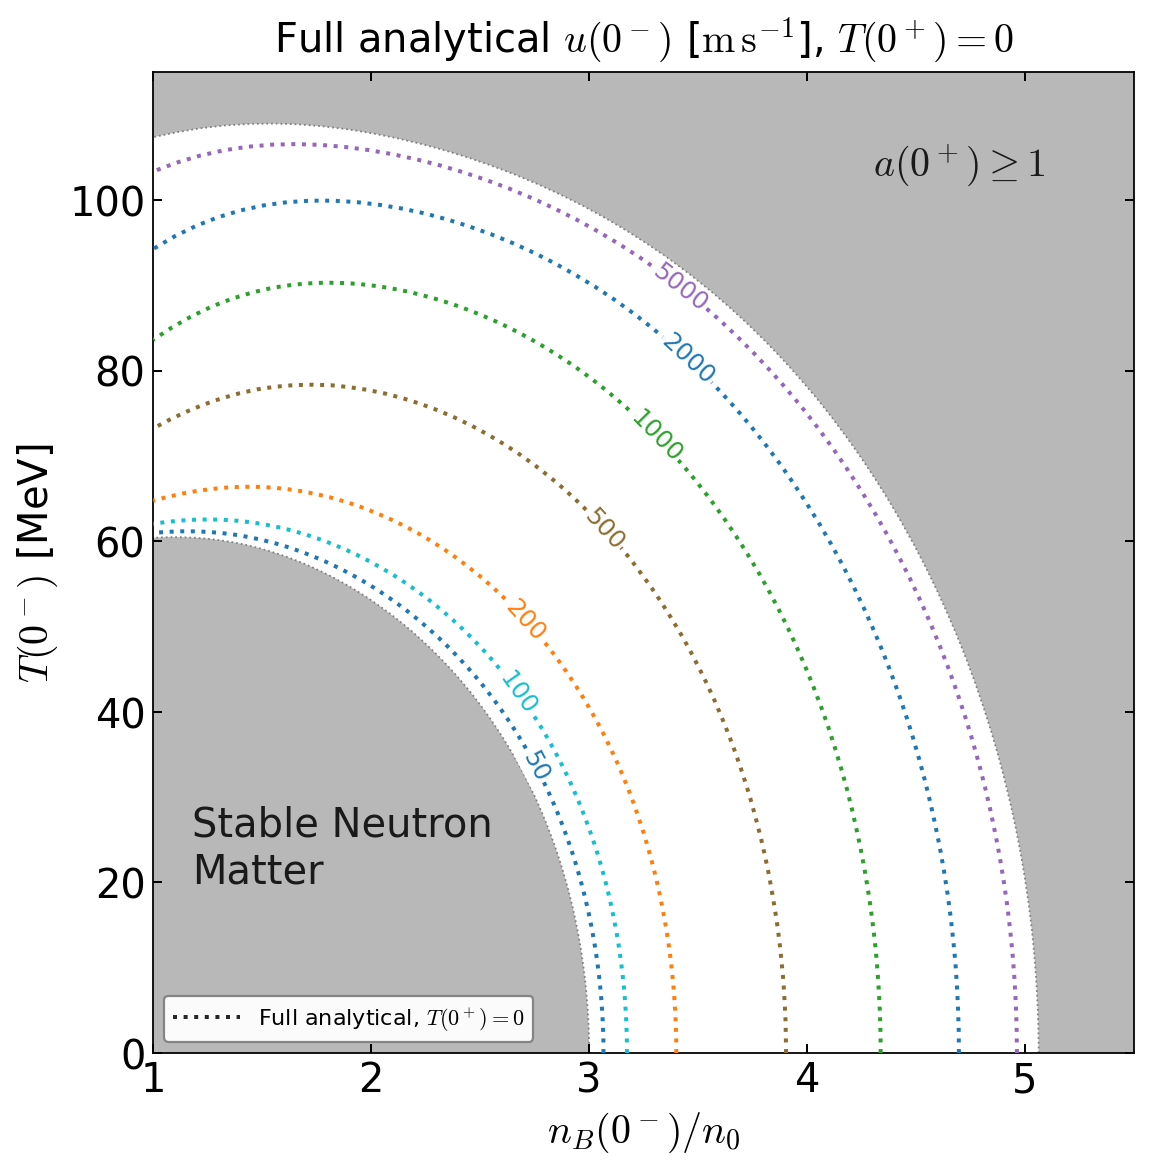

In [15]:
# Tunable plotting parameters
FIGURE_SIZE = (7.2, 7.2)
FIGURE_DPI = 160
EXPORT_DPI = 220
EXPORT_FORMATS = ("png", "pdf")
BACKGROUND_COLOR = "white"
CONSTRAINED_LAYOUT = True
FONT_FAMILY = "DejaVu Sans"
MATH_FONTSET = "cm"
TITLE_FONT_SIZE = 18
TITLE_PAD = 9
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
CONTOUR_LABEL_FONT_SIZE = 11
CONTOUR_LABEL_FACE_COLOR = "white"
CONTOUR_LABEL_EDGE_COLOR = "none"
CONTOUR_LABEL_BOX_PADDING = .09
CONTOUR_LABEL_ALPHA = .95
LABEL_HORIZONTAL_ALIGNMENT = "center"
LABEL_VERTICAL_ALIGNMENT = "center"
LABEL_ROTATION_MODE = "anchor"
CONTOUR_LABEL_FORMAT = "g"
LINE_WIDTH = 1.8
NUMERICAL_LINE_WIDTH = 1.5
LINE_ALPHA = 1.
CONTOUR_ZORDER = 3
LABEL_ZORDER = 5
LEVELS_M_S = (50., 100., 200., 500., 1000., 2000., 5000.)
LEVEL_COLORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c", "#1f77b4", "#9467bd")
METHOD_STYLES = {"analytic": ":", "semi_analytic": "--"}
METHOD_LABELS = {"analytic": r"Full analytical, $T(0^+)=0$", "semi_analytic": r"Semi-analytical, $T(0^+)=0$"}
LABEL_TEMPERATURES = {"analytic": {50.: 33., 100.: 42., 200.: 51., 500.: 61., 1000.: 72., 2000.: 81., 5000.: 90.},
                      "semi_analytic": {50.: 38., 100.: 44., 200.: 53., 500.: 63., 1000.: 72., 2000.: 81., 5000.: 89.}}
NUMERICAL_LINE_STYLE = "-"
NUMERICAL_LABEL = r"Numerical, $T(0^+)=0.1\,\mathrm{MeV}$"
NUMERICAL_SPLIT_LEVEL_M_S = 5000.
EXCLUDED_REGION_COLOR = "0.72"
EXCLUDED_REGION_ALPHA = 1.
EXCLUDED_REGION_ZORDER = 0
EXCLUDED_REGION_EDGE_WIDTH = 0
BOUNDARY_COLOR = "0.5"
BOUNDARY_LINE_WIDTH = .8
BOUNDARY_ZORDER = 1
REGION_LABEL = "Stable Neutron\nMatter"
REGION_LABEL_POSITION = (1.18, 20.)
REGION_LABEL_FONT_SIZE = 18
REGION_LABEL_COLOR = "0.10"
CEILING_LABEL = r"$a(0^+)\geq 1$"
CEILING_LABEL_POSITION = (4.3, 103.)
X_LIMITS = (1., 5.5)
Y_LIMITS_MEV = (0., 115.)
X_TICKS = (1., 2., 3., 4., 5.)
Y_TICKS_MEV = (0., 20., 40., 60., 80., 100.)
X_SCALE = "linear"
Y_SCALE = "linear"
BOX_ASPECT = 1.
X_LABEL = r"$n_B(0^-)/n_0$"
Y_LABEL = r"$T(0^-)$ [MeV]"
TICK_DIRECTION = "in"
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4
TICK_WIDTH = .9
SPINE_LINE_WIDTH = .8
GRID_ENABLED = False
LEGEND_FONT_SIZE = 10
LEGEND_LOCATION = "lower left"
LEGEND_FRAME_ALPHA = .95
LEGEND_FACE_COLOR = "white"
LEGEND_EDGE_COLOR = "0.5"
LEGEND_COLOR = "0.15"
LEGEND_HANDLE_LENGTH = 3.
PLOT_METHODS = ('analytic',)
SHOW_NUMERICAL = False
SHADE_EXCLUSIONS = True
TITLE = 'Full analytical $u(0^-)$ [$\\mathrm{m\\,s^{-1}}$], $T(0^+)=0$'
OUTPUT_STEM = "local_analysis_results/26-10-26/adiabatic-full-analytical-cold"

with plt.rc_context({"font.family": FONT_FAMILY, "mathtext.fontset": MATH_FONTSET}):
    figure, axis = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI,
        constrained_layout=CONSTRAINED_LAYOUT, facecolor=BACKGROUND_COLOR)
    axis.set_facecolor(BACKGROUND_COLOR)
    if SHADE_EXCLUSIONS:
        for polygon in excluded_polygons(cold, PLOT_METHODS[0], X_LIMITS, Y_LIMITS_MEV):
            axis.fill(polygon[:,0], polygon[:,1], color=EXCLUDED_REGION_COLOR,
                alpha=EXCLUDED_REGION_ALPHA, zorder=EXCLUDED_REGION_ZORDER, linewidth=EXCLUDED_REGION_EDGE_WIDTH)
        axis.text(*REGION_LABEL_POSITION, REGION_LABEL, fontsize=REGION_LABEL_FONT_SIZE,
                  color=REGION_LABEL_COLOR, zorder=LABEL_ZORDER)
        if boundary_segments(cold, PLOT_METHODS[0], "composition_ceiling"):
            axis.text(*CEILING_LABEL_POSITION, CEILING_LABEL, fontsize=REGION_LABEL_FONT_SIZE,
                      color=REGION_LABEL_COLOR, zorder=LABEL_ZORDER)
    if SHOW_NUMERICAL:
        for grid, selected in ((NR_GRID, [v for v in LEVELS_M_S if v < NUMERICAL_SPLIT_LEVEL_M_S]),
                               (NR_OUTER_STRIP, [v for v in LEVELS_M_S if v == NUMERICAL_SPLIT_LEVEL_M_S])):
            if selected:
                colors = [LEVEL_COLORS[LEVELS_M_S.index(v)] for v in selected]
                axis.contour(*grid, levels=selected, colors=colors,
                    linestyles=NUMERICAL_LINE_STYLE, linewidths=NUMERICAL_LINE_WIDTH,
                    alpha=LINE_ALPHA, zorder=CONTOUR_ZORDER)
    handles = []
    if SHOW_NUMERICAL:
        handles.append(Line2D([], [], color=LEGEND_COLOR, linestyle=NUMERICAL_LINE_STYLE,
                             linewidth=NUMERICAL_LINE_WIDTH, label=NUMERICAL_LABEL))
    for method in PLOT_METHODS:
        for level,color in zip(LEVELS_M_S, LEVEL_COLORS):
            curves = segments(cold, method, level)
            for curve in curves:
                axis.plot(curve[:,0], curve[:,1], color=color, linestyle=METHOD_STYLES[method],
                    linewidth=LINE_WIDTH, alpha=LINE_ALPHA, zorder=CONTOUR_ZORDER)
            if curves:
                curve = max(curves, key=len)
                position,angle = label_point(curve, LABEL_TEMPERATURES[method][level], X_LIMITS, Y_LIMITS_MEV)
                axis.text(*position, format(level, CONTOUR_LABEL_FORMAT), color=color,
                    fontsize=CONTOUR_LABEL_FONT_SIZE, rotation=angle, rotation_mode=LABEL_ROTATION_MODE,
                    ha=LABEL_HORIZONTAL_ALIGNMENT, va=LABEL_VERTICAL_ALIGNMENT, zorder=LABEL_ZORDER,
                    bbox=dict(facecolor=CONTOUR_LABEL_FACE_COLOR, edgecolor=CONTOUR_LABEL_EDGE_COLOR,
                        alpha=CONTOUR_LABEL_ALPHA, boxstyle=f"square,pad={CONTOUR_LABEL_BOX_PADDING}"))
        for name in ("stable_matter", "composition_ceiling"):
            for curve in boundary_segments(cold, method, name):
                axis.plot(curve[:,0], curve[:,1], color=BOUNDARY_COLOR,
                    linestyle=METHOD_STYLES[method], linewidth=BOUNDARY_LINE_WIDTH, zorder=BOUNDARY_ZORDER)
        handles.append(Line2D([], [], color=LEGEND_COLOR, linestyle=METHOD_STYLES[method],
                             linewidth=LINE_WIDTH, label=METHOD_LABELS[method]))
    axis.legend(handles=handles, loc=LEGEND_LOCATION, fontsize=LEGEND_FONT_SIZE,
        framealpha=LEGEND_FRAME_ALPHA, facecolor=LEGEND_FACE_COLOR, edgecolor=LEGEND_EDGE_COLOR,
        handlelength=LEGEND_HANDLE_LENGTH)
    axis.set(xlim=X_LIMITS, ylim=Y_LIMITS_MEV, xscale=X_SCALE, yscale=Y_SCALE,
             xticks=X_TICKS, yticks=Y_TICKS_MEV)
    axis.set_box_aspect(BOX_ASPECT)
    axis.set_xlabel(X_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_ylabel(Y_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_title(TITLE, fontsize=TITLE_FONT_SIZE, pad=TITLE_PAD)
    axis.tick_params(direction=TICK_DIRECTION, top=TICKS_TOP, right=TICKS_RIGHT,
                    length=TICK_LENGTH, width=TICK_WIDTH, labelsize=TICK_LABEL_FONT_SIZE)
    axis.grid(GRID_ENABLED)
    for spine in axis.spines.values():
        spine.set_linewidth(SPINE_LINE_WIDTH)
    output = ROOT / OUTPUT_STEM
    output.parent.mkdir(parents=True, exist_ok=True)
    for extension in EXPORT_FORMATS:
        figure.savefig(output.with_suffix("."+extension), dpi=EXPORT_DPI, facecolor=BACKGROUND_COLOR)
    print("Saved", output, "— levels outside window:",
          {m:cold["coverage"][m]["outside_window_levels"] for m in PLOT_METHODS})
    plt.show()


### Semi-analytical

Saved /Users/janshao/NSM_related/local_analysis_results/26-10-26/adiabatic-semi-analytical-cold — levels outside window: {'semi_analytic': []}


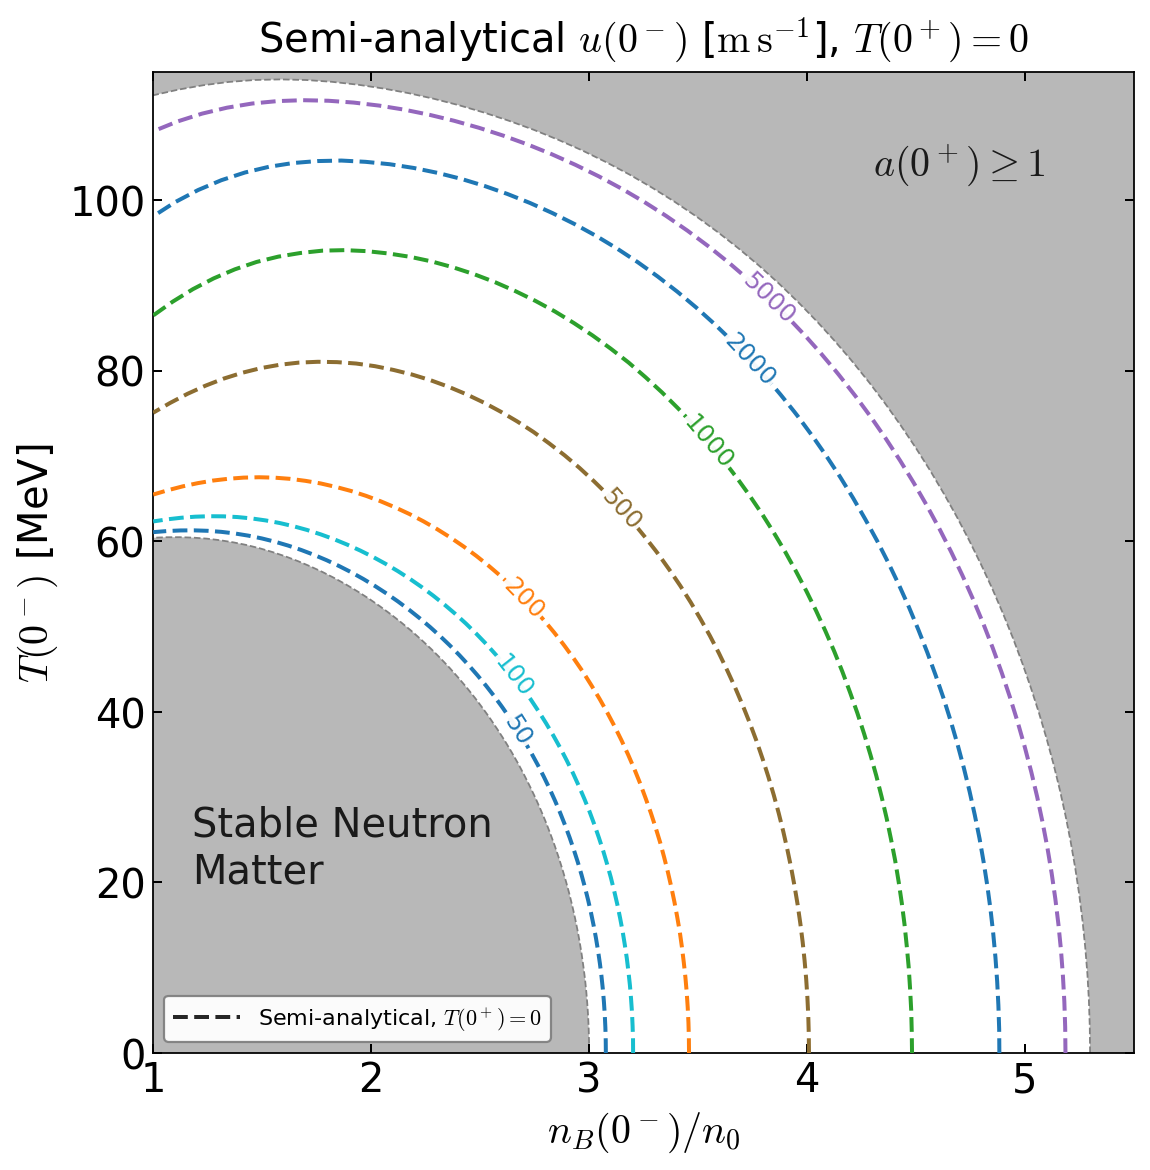

In [6]:
# Tunable plotting parameters
FIGURE_SIZE = (7.2, 7.2)
FIGURE_DPI = 160
EXPORT_DPI = 220
EXPORT_FORMATS = ("png", "pdf")
BACKGROUND_COLOR = "white"
CONSTRAINED_LAYOUT = True
FONT_FAMILY = "DejaVu Sans"
MATH_FONTSET = "cm"
TITLE_FONT_SIZE = 18
TITLE_PAD = 9
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
CONTOUR_LABEL_FONT_SIZE = 11
CONTOUR_LABEL_FACE_COLOR = "white"
CONTOUR_LABEL_EDGE_COLOR = "none"
CONTOUR_LABEL_BOX_PADDING = .09
CONTOUR_LABEL_ALPHA = .95
LABEL_HORIZONTAL_ALIGNMENT = "center"
LABEL_VERTICAL_ALIGNMENT = "center"
LABEL_ROTATION_MODE = "anchor"
CONTOUR_LABEL_FORMAT = "g"
LINE_WIDTH = 1.8
NUMERICAL_LINE_WIDTH = 1.5
LINE_ALPHA = 1.
CONTOUR_ZORDER = 3
LABEL_ZORDER = 5
LEVELS_M_S = (50., 100., 200., 500., 1000., 2000., 5000.)
LEVEL_COLORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c", "#1f77b4", "#9467bd")
METHOD_STYLES = {"analytic": ":", "semi_analytic": "--"}
METHOD_LABELS = {"analytic": r"Full analytical, $T(0^+)=0$", "semi_analytic": r"Semi-analytical, $T(0^+)=0$"}
LABEL_TEMPERATURES = {"analytic": {50.: 33., 100.: 42., 200.: 51., 500.: 61., 1000.: 102., 2000.: 90., 5000.: 97.},
                      "semi_analytic": {50.: 38., 100.: 44., 200.: 53., 500.: 63., 1000.: 72., 2000.: 81., 5000.: 89.}}
NUMERICAL_LINE_STYLE = "-"
NUMERICAL_LABEL = r"Numerical, $T(0^+)=0.1\,\mathrm{MeV}$"
NUMERICAL_SPLIT_LEVEL_M_S = 5000.
EXCLUDED_REGION_COLOR = "0.72"
EXCLUDED_REGION_ALPHA = 1.
EXCLUDED_REGION_ZORDER = 0
EXCLUDED_REGION_EDGE_WIDTH = 0
BOUNDARY_COLOR = "0.5"
BOUNDARY_LINE_WIDTH = .8
BOUNDARY_ZORDER = 1
REGION_LABEL = "Stable Neutron\nMatter"
REGION_LABEL_POSITION = (1.18, 20.)
REGION_LABEL_FONT_SIZE = 18
REGION_LABEL_COLOR = "0.10"
CEILING_LABEL = r"$a(0^+)\geq 1$"
CEILING_LABEL_POSITION = (4.3, 103.)
X_LIMITS = (1., 5.5)
Y_LIMITS_MEV = (0., 115.)
X_TICKS = (1., 2., 3., 4., 5.)
Y_TICKS_MEV = (0., 20., 40., 60., 80., 100.)
X_SCALE = "linear"
Y_SCALE = "linear"
BOX_ASPECT = 1.
X_LABEL = r"$n_B(0^-)/n_0$"
Y_LABEL = r"$T(0^-)$ [MeV]"
TICK_DIRECTION = "in"
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4
TICK_WIDTH = .9
SPINE_LINE_WIDTH = .8
GRID_ENABLED = False
LEGEND_FONT_SIZE = 10
LEGEND_LOCATION = "lower left"
LEGEND_FRAME_ALPHA = .95
LEGEND_FACE_COLOR = "white"
LEGEND_EDGE_COLOR = "0.5"
LEGEND_COLOR = "0.15"
LEGEND_HANDLE_LENGTH = 3.
PLOT_METHODS = ('semi_analytic',)
SHOW_NUMERICAL = False
SHADE_EXCLUSIONS = True
TITLE = 'Semi-analytical $u(0^-)$ [$\\mathrm{m\\,s^{-1}}$], $T(0^+)=0$'
OUTPUT_STEM = "local_analysis_results/26-10-26/adiabatic-semi-analytical-cold"

with plt.rc_context({"font.family": FONT_FAMILY, "mathtext.fontset": MATH_FONTSET}):
    figure, axis = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI,
        constrained_layout=CONSTRAINED_LAYOUT, facecolor=BACKGROUND_COLOR)
    axis.set_facecolor(BACKGROUND_COLOR)
    if SHADE_EXCLUSIONS:
        for polygon in excluded_polygons(cold, PLOT_METHODS[0], X_LIMITS, Y_LIMITS_MEV):
            axis.fill(polygon[:,0], polygon[:,1], color=EXCLUDED_REGION_COLOR,
                alpha=EXCLUDED_REGION_ALPHA, zorder=EXCLUDED_REGION_ZORDER, linewidth=EXCLUDED_REGION_EDGE_WIDTH)
        axis.text(*REGION_LABEL_POSITION, REGION_LABEL, fontsize=REGION_LABEL_FONT_SIZE,
                  color=REGION_LABEL_COLOR, zorder=LABEL_ZORDER)
        if boundary_segments(cold, PLOT_METHODS[0], "composition_ceiling"):
            axis.text(*CEILING_LABEL_POSITION, CEILING_LABEL, fontsize=REGION_LABEL_FONT_SIZE,
                      color=REGION_LABEL_COLOR, zorder=LABEL_ZORDER)
    if SHOW_NUMERICAL:
        for grid, selected in ((NR_GRID, [v for v in LEVELS_M_S if v < NUMERICAL_SPLIT_LEVEL_M_S]),
                               (NR_OUTER_STRIP, [v for v in LEVELS_M_S if v == NUMERICAL_SPLIT_LEVEL_M_S])):
            if selected:
                colors = [LEVEL_COLORS[LEVELS_M_S.index(v)] for v in selected]
                axis.contour(*grid, levels=selected, colors=colors,
                    linestyles=NUMERICAL_LINE_STYLE, linewidths=NUMERICAL_LINE_WIDTH,
                    alpha=LINE_ALPHA, zorder=CONTOUR_ZORDER)
    handles = []
    if SHOW_NUMERICAL:
        handles.append(Line2D([], [], color=LEGEND_COLOR, linestyle=NUMERICAL_LINE_STYLE,
                             linewidth=NUMERICAL_LINE_WIDTH, label=NUMERICAL_LABEL))
    for method in PLOT_METHODS:
        for level,color in zip(LEVELS_M_S, LEVEL_COLORS):
            curves = segments(cold, method, level)
            for curve in curves:
                axis.plot(curve[:,0], curve[:,1], color=color, linestyle=METHOD_STYLES[method],
                    linewidth=LINE_WIDTH, alpha=LINE_ALPHA, zorder=CONTOUR_ZORDER)
            if curves:
                curve = max(curves, key=len)
                position,angle = label_point(curve, LABEL_TEMPERATURES[method][level], X_LIMITS, Y_LIMITS_MEV)
                axis.text(*position, format(level, CONTOUR_LABEL_FORMAT), color=color,
                    fontsize=CONTOUR_LABEL_FONT_SIZE, rotation=angle, rotation_mode=LABEL_ROTATION_MODE,
                    ha=LABEL_HORIZONTAL_ALIGNMENT, va=LABEL_VERTICAL_ALIGNMENT, zorder=LABEL_ZORDER,
                    bbox=dict(facecolor=CONTOUR_LABEL_FACE_COLOR, edgecolor=CONTOUR_LABEL_EDGE_COLOR,
                        alpha=CONTOUR_LABEL_ALPHA, boxstyle=f"square,pad={CONTOUR_LABEL_BOX_PADDING}"))
        for name in ("stable_matter", "composition_ceiling"):
            for curve in boundary_segments(cold, method, name):
                axis.plot(curve[:,0], curve[:,1], color=BOUNDARY_COLOR,
                    linestyle=METHOD_STYLES[method], linewidth=BOUNDARY_LINE_WIDTH, zorder=BOUNDARY_ZORDER)
        handles.append(Line2D([], [], color=LEGEND_COLOR, linestyle=METHOD_STYLES[method],
                             linewidth=LINE_WIDTH, label=METHOD_LABELS[method]))
    axis.legend(handles=handles, loc=LEGEND_LOCATION, fontsize=LEGEND_FONT_SIZE,
        framealpha=LEGEND_FRAME_ALPHA, facecolor=LEGEND_FACE_COLOR, edgecolor=LEGEND_EDGE_COLOR,
        handlelength=LEGEND_HANDLE_LENGTH)
    axis.set(xlim=X_LIMITS, ylim=Y_LIMITS_MEV, xscale=X_SCALE, yscale=Y_SCALE,
             xticks=X_TICKS, yticks=Y_TICKS_MEV)
    axis.set_box_aspect(BOX_ASPECT)
    axis.set_xlabel(X_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_ylabel(Y_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_title(TITLE, fontsize=TITLE_FONT_SIZE, pad=TITLE_PAD)
    axis.tick_params(direction=TICK_DIRECTION, top=TICKS_TOP, right=TICKS_RIGHT,
                    length=TICK_LENGTH, width=TICK_WIDTH, labelsize=TICK_LABEL_FONT_SIZE)
    axis.grid(GRID_ENABLED)
    for spine in axis.spines.values():
        spine.set_linewidth(SPINE_LINE_WIDTH)
    output = ROOT / OUTPUT_STEM
    output.parent.mkdir(parents=True, exist_ok=True)
    for extension in EXPORT_FORMATS:
        figure.savefig(output.with_suffix("."+extension), dpi=EXPORT_DPI, facecolor=BACKGROUND_COLOR)
    print("Saved", output, "— levels outside window:",
          {m:cold["coverage"][m]["outside_window_levels"] for m in PLOT_METHODS})
    plt.show()


### Analytical methods and numerical reference

Saved /Users/janshao/NSM_related/local_analysis_results/26-10-26/adiabatic-cold-analytical-vs-numerical — levels outside window: {'analytic': [], 'semi_analytic': []}


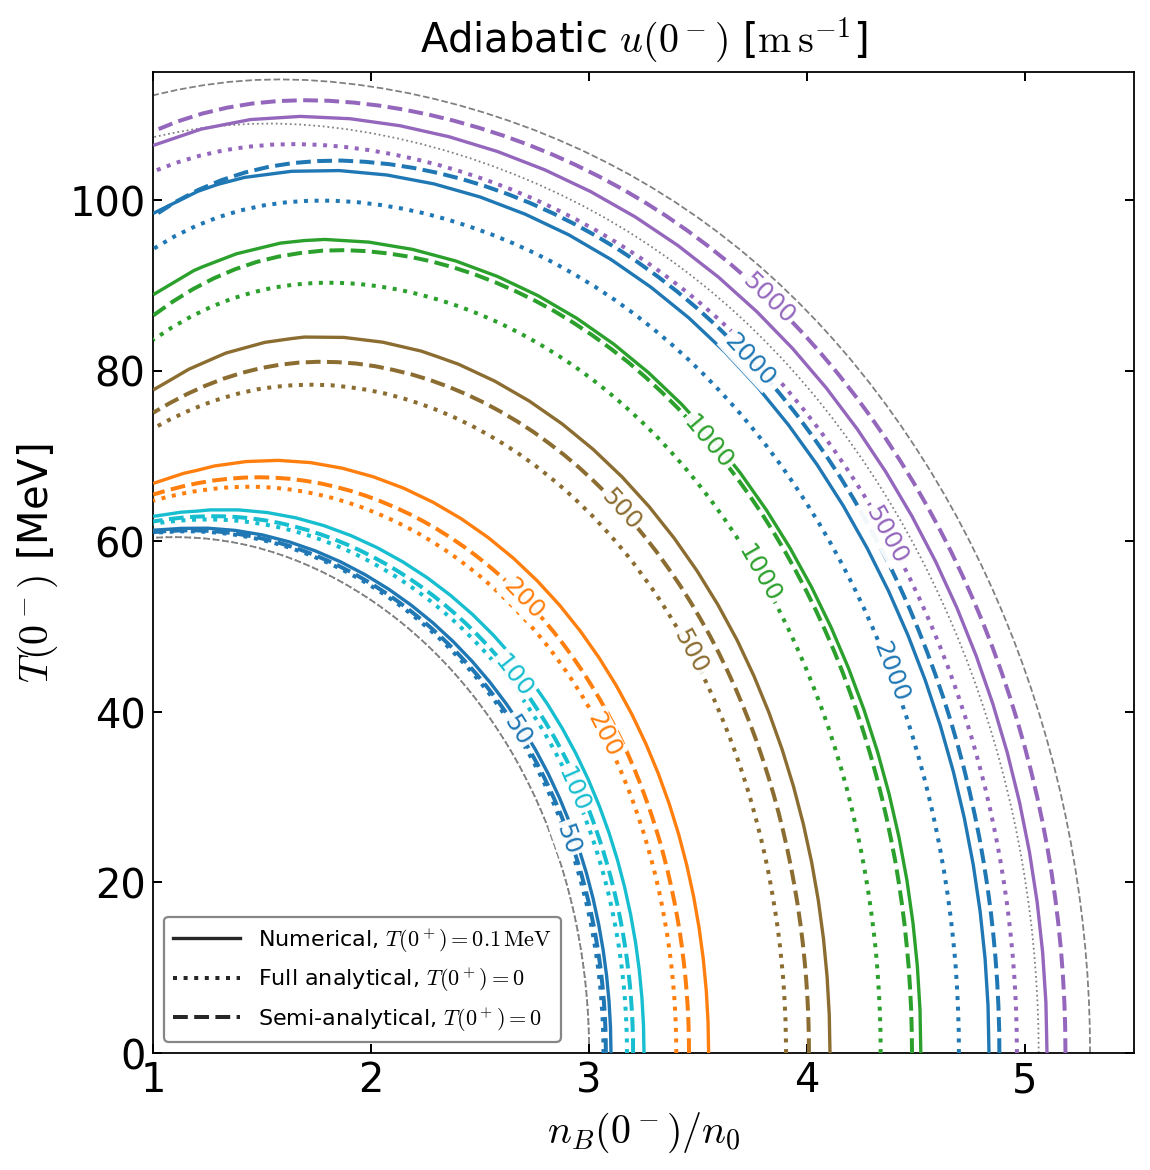

In [16]:
# Tunable plotting parameters
FIGURE_SIZE = (7.2, 7.2)
FIGURE_DPI = 160
EXPORT_DPI = 220
EXPORT_FORMATS = ("png", "pdf")
BACKGROUND_COLOR = "white"
CONSTRAINED_LAYOUT = True
FONT_FAMILY = "DejaVu Sans"
MATH_FONTSET = "cm"
TITLE_FONT_SIZE = 18
TITLE_PAD = 9
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
CONTOUR_LABEL_FONT_SIZE = 11
CONTOUR_LABEL_FACE_COLOR = "white"
CONTOUR_LABEL_EDGE_COLOR = "none"
CONTOUR_LABEL_BOX_PADDING = .09
CONTOUR_LABEL_ALPHA = .95
LABEL_HORIZONTAL_ALIGNMENT = "center"
LABEL_VERTICAL_ALIGNMENT = "center"
LABEL_ROTATION_MODE = "anchor"
CONTOUR_LABEL_FORMAT = "g"
LINE_WIDTH = 1.8
NUMERICAL_LINE_WIDTH = 1.5
LINE_ALPHA = 1.
CONTOUR_ZORDER = 3
LABEL_ZORDER = 5
LEVELS_M_S = (50., 100., 200., 500., 1000., 2000., 5000.)
LEVEL_COLORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c", "#1f77b4", "#9467bd")
METHOD_STYLES = {"analytic": ":", "semi_analytic": "--"}
METHOD_LABELS = {"analytic": r"Full analytical, $T(0^+)=0$", "semi_analytic": r"Semi-analytical, $T(0^+)=0$"}
LABEL_TEMPERATURES = {"analytic": {50.: 25., 100.: 31., 200.: 38., 500.: 47., 1000.: 57., 2000.: 45., 5000.: 60.},
                      "semi_analytic": {50.: 38., 100.: 44., 200.: 53., 500.: 63., 1000.: 72., 2000.: 81., 5000.: 89.}}
NUMERICAL_LINE_STYLE = "-"
NUMERICAL_LABEL = r"Numerical, $T(0^+)=0.1\,\mathrm{MeV}$"
NUMERICAL_SPLIT_LEVEL_M_S = 5000.
EXCLUDED_REGION_COLOR = "0.72"
EXCLUDED_REGION_ALPHA = 1.
EXCLUDED_REGION_ZORDER = 0
EXCLUDED_REGION_EDGE_WIDTH = 0
BOUNDARY_COLOR = "0.5"
BOUNDARY_LINE_WIDTH = .8
BOUNDARY_ZORDER = 1
REGION_LABEL = "Stable Neutron\nMatter"
REGION_LABEL_POSITION = (1.18, 20.)
REGION_LABEL_FONT_SIZE = 18
REGION_LABEL_COLOR = "0.10"
CEILING_LABEL = r"$a(0^+)\geq 1$"
CEILING_LABEL_POSITION = (4.3, 103.)
X_LIMITS = (1., 5.5)
Y_LIMITS_MEV = (0., 115.)
X_TICKS = (1., 2., 3., 4., 5.)
Y_TICKS_MEV = (0., 20., 40., 60., 80., 100.)
X_SCALE = "linear"
Y_SCALE = "linear"
BOX_ASPECT = 1.
X_LABEL = r"$n_B(0^-)/n_0$"
Y_LABEL = r"$T(0^-)$ [MeV]"
TICK_DIRECTION = "in"
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4
TICK_WIDTH = .9
SPINE_LINE_WIDTH = .8
GRID_ENABLED = False
LEGEND_FONT_SIZE = 10
LEGEND_LOCATION = "lower left"
LEGEND_FRAME_ALPHA = .95
LEGEND_FACE_COLOR = "white"
LEGEND_EDGE_COLOR = "0.5"
LEGEND_COLOR = "0.15"
LEGEND_HANDLE_LENGTH = 3.
PLOT_METHODS = ('analytic', 'semi_analytic')
SHOW_NUMERICAL = True
SHADE_EXCLUSIONS = False
TITLE = 'Adiabatic $u(0^-)$ [$\\mathrm{m\\,s^{-1}}$]'
OUTPUT_STEM = "local_analysis_results/26-10-26/adiabatic-cold-analytical-vs-numerical"

with plt.rc_context({"font.family": FONT_FAMILY, "mathtext.fontset": MATH_FONTSET}):
    figure, axis = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI,
        constrained_layout=CONSTRAINED_LAYOUT, facecolor=BACKGROUND_COLOR)
    axis.set_facecolor(BACKGROUND_COLOR)
    if SHADE_EXCLUSIONS:
        for polygon in excluded_polygons(cold, PLOT_METHODS[0], X_LIMITS, Y_LIMITS_MEV):
            axis.fill(polygon[:,0], polygon[:,1], color=EXCLUDED_REGION_COLOR,
                alpha=EXCLUDED_REGION_ALPHA, zorder=EXCLUDED_REGION_ZORDER, linewidth=EXCLUDED_REGION_EDGE_WIDTH)
        axis.text(*REGION_LABEL_POSITION, REGION_LABEL, fontsize=REGION_LABEL_FONT_SIZE,
                  color=REGION_LABEL_COLOR, zorder=LABEL_ZORDER)
        if boundary_segments(cold, PLOT_METHODS[0], "composition_ceiling"):
            axis.text(*CEILING_LABEL_POSITION, CEILING_LABEL, fontsize=REGION_LABEL_FONT_SIZE,
                      color=REGION_LABEL_COLOR, zorder=LABEL_ZORDER)
    if SHOW_NUMERICAL:
        for grid, selected in ((NR_GRID, [v for v in LEVELS_M_S if v < NUMERICAL_SPLIT_LEVEL_M_S]),
                               (NR_OUTER_STRIP, [v for v in LEVELS_M_S if v == NUMERICAL_SPLIT_LEVEL_M_S])):
            if selected:
                colors = [LEVEL_COLORS[LEVELS_M_S.index(v)] for v in selected]
                axis.contour(*grid, levels=selected, colors=colors,
                    linestyles=NUMERICAL_LINE_STYLE, linewidths=NUMERICAL_LINE_WIDTH,
                    alpha=LINE_ALPHA, zorder=CONTOUR_ZORDER)
    handles = []
    if SHOW_NUMERICAL:
        handles.append(Line2D([], [], color=LEGEND_COLOR, linestyle=NUMERICAL_LINE_STYLE,
                             linewidth=NUMERICAL_LINE_WIDTH, label=NUMERICAL_LABEL))
    for method in PLOT_METHODS:
        for level,color in zip(LEVELS_M_S, LEVEL_COLORS):
            curves = segments(cold, method, level)
            for curve in curves:
                axis.plot(curve[:,0], curve[:,1], color=color, linestyle=METHOD_STYLES[method],
                    linewidth=LINE_WIDTH, alpha=LINE_ALPHA, zorder=CONTOUR_ZORDER)
            if curves:
                curve = max(curves, key=len)
                position,angle = label_point(curve, LABEL_TEMPERATURES[method][level], X_LIMITS, Y_LIMITS_MEV)
                axis.text(*position, format(level, CONTOUR_LABEL_FORMAT), color=color,
                    fontsize=CONTOUR_LABEL_FONT_SIZE, rotation=angle, rotation_mode=LABEL_ROTATION_MODE,
                    ha=LABEL_HORIZONTAL_ALIGNMENT, va=LABEL_VERTICAL_ALIGNMENT, zorder=LABEL_ZORDER,
                    bbox=dict(facecolor=CONTOUR_LABEL_FACE_COLOR, edgecolor=CONTOUR_LABEL_EDGE_COLOR,
                        alpha=CONTOUR_LABEL_ALPHA, boxstyle=f"square,pad={CONTOUR_LABEL_BOX_PADDING}"))
        for name in ("stable_matter", "composition_ceiling"):
            for curve in boundary_segments(cold, method, name):
                axis.plot(curve[:,0], curve[:,1], color=BOUNDARY_COLOR,
                    linestyle=METHOD_STYLES[method], linewidth=BOUNDARY_LINE_WIDTH, zorder=BOUNDARY_ZORDER)
        handles.append(Line2D([], [], color=LEGEND_COLOR, linestyle=METHOD_STYLES[method],
                             linewidth=LINE_WIDTH, label=METHOD_LABELS[method]))
    axis.legend(handles=handles, loc=LEGEND_LOCATION, fontsize=LEGEND_FONT_SIZE,
        framealpha=LEGEND_FRAME_ALPHA, facecolor=LEGEND_FACE_COLOR, edgecolor=LEGEND_EDGE_COLOR,
        handlelength=LEGEND_HANDLE_LENGTH)
    axis.set(xlim=X_LIMITS, ylim=Y_LIMITS_MEV, xscale=X_SCALE, yscale=Y_SCALE,
             xticks=X_TICKS, yticks=Y_TICKS_MEV)
    axis.set_box_aspect(BOX_ASPECT)
    axis.set_xlabel(X_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_ylabel(Y_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_title(TITLE, fontsize=TITLE_FONT_SIZE, pad=TITLE_PAD)
    axis.tick_params(direction=TICK_DIRECTION, top=TICKS_TOP, right=TICKS_RIGHT,
                    length=TICK_LENGTH, width=TICK_WIDTH, labelsize=TICK_LABEL_FONT_SIZE)
    axis.grid(GRID_ENABLED)
    for spine in axis.spines.values():
        spine.set_linewidth(SPINE_LINE_WIDTH)
    output = ROOT / OUTPUT_STEM
    output.parent.mkdir(parents=True, exist_ok=True)
    for extension in EXPORT_FORMATS:
        figure.savefig(output.with_suffix("."+extension), dpi=EXPORT_DPI, facecolor=BACKGROUND_COLOR)
    print("Saved", output, "— levels outside window:",
          {m:cold["coverage"][m]["outside_window_levels"] for m in PLOT_METHODS})
    plt.show()


### Reproducing the cold scans

Use `new_paper_calculations/26-10-26/local/run_adiabatic_contours.py` with a working SciPy runtime; the cluster entry point is in the sibling `cluster/` folder. Both use the same engine and frozen coordinate/calibration input. Restart the identical command to resume. The plotting cells read saved results and perform no EOS or front solves.

The README records commands, numerical coverage, and the independent cold-limit verification. Pointwise records retain endpoint quantities, integrals, source hashes and retry history.

The combined plotting file now contains the corrected full-analytical branch and the unchanged semi-analytical branch. It records separate `method_identities`, `record_directories`, and `source_manifests`; it is not a resumable single-scan checkpoint. Resume the corrected analytic scan with `--method analytic --output new_paper_calculations/26-10-26/local/adiabatic-T0plus0-xi-minus0p85-second-order.npy`. The original combined manifest is archived at `local_analysis_results/26-10-26-second-order/notebook-refresh/adiabatic-T0plus0-xi-minus0p85-leading-density.npy`.